# F3-Z1 input audit

Input quality and usable evidence windows for BQ2, before modelling. Snapshot dated 30 October 2026; source hashes are saved in the provenance record.

## tl;dr

- The source grids are complete and unique, but measurement availability is **86.06% for the AC total**, **63.62% for paired temperature/RH**, and **61.92% jointly**, after existing cleaning.
- Environmental gaps span **12 September 2018–6 March 2019** and **28 November–19 December 2019**. The latter limits cool-season evidence more than the earlier guide indicated.
- July–August is the clearest initial cross-year window. At the illustrative 95% daily gate, 39/42 inferred working days in 2018 and 40/41 in 2019 have sufficient cleaned joint coverage; raw-observed counts are 29 and 40.
- All **626 start-ups** and **583 shutdowns** pass the 30-minute continuity check. Usable 60-minute start-up windows fall to **444 with cleaned inputs** and **355 without filled source readings**. In July–August specifically, cleaned/raw-observed start-up windows are **81/29 in 2018** and **78/71 in 2019**. That asymmetry needs a sensitivity check before comparing performance.
- Raw temperature/RH have no hour-long exact flatlines. One 79-minute cleaned-temperature plateau bridges a four-minute source gap; these checks cannot rule out drift.
- Hourly exports reconcile exactly with cleaned inputs; all 13,176 weather hours are present. Building-clock alignment remains unverified because timestamps carry no offset.

**Decision:** retain F3-Z1 for further investigation using explicitly gated periods and interpolation sensitivity. No model has been fitted and no degradation or mould finding is established.

## Context & Methods

F3-Z1 has four AC channels, one plug-load channel, and paired temperature/RH readings. The requested window is 1 July 2018–31 December 2019: **790,560 expected one-minute slots**. Missing source measurements remain unknown.

### Key assumptions

- AC coverage requires **all four meters** at the same minute. Environmental coverage requires **both temperature and RH**. Joint coverage requires all six fields.
- Raw and cleaned coverage are separate. Cleaned data include existing short-gap interpolation; source-to-clean differences are checked directly and against the quality log.
- Range checks reuse upstream rules: temperature 15–40 °C, RH 0–100%, nonnegative power. Passing these checks does not establish calibration or an AC fault-free baseline.
- Candidate daily eligibility requires 95% of **all 1,440 daily minutes**, with 90% and 100% sensitivity checks. These are audit choices, not standards. `working day` is an existing energy-inferred label, not measured occupancy.
- Event QA checks 30 continuous power minutes on either side of a transition, then a sustained 60-minute state and paired environmental observations. The raw-observed variant excludes filled measurements in required windows. It does not estimate cooling response.
- Exact sensor repeats of at least 60 minutes are a QA screen; repetitions do not by themselves prove a faulty sensor. Sensor drift cannot be ruled out without calibration/reference data.
- Building CSV timestamps are naive. The ERA5 loader requests Asia/Bangkok; matching timestamps do not independently confirm clock alignment.

Implementation is inspectable in `f3z1_audit.py`. Calculations below reuse the existing shared helper for AC thresholds/events and weather features.

In [1]:
from pathlib import Path
import json
import hashlib
import sys
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

%matplotlib inline
# Locate this checkout from the repository root or any notebook subfolder.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "AGENTS.md").is_file()
                 and (p / "mould-ac-degradation/bq2_utils.ipynb").is_file())
analysis_dir = repo_root / "mould-ac-degradation"
sys.path.insert(0, str(analysis_dir / "src"))
RUN_CHECKS = False
helper_notebook = analysis_dir / "bq2_utils.ipynb"
get_ipython().run_line_magic("run", f'-i "{helper_notebook}"')

from bq2 import input_audit as audit
assert (repo_root / "data-cleaning").is_dir(), "Missing upstream inputs"
output_dir = Path(analysis_dir / "outputs/f3z1-input-audit")
output_dir.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(repo_root / "baseline"))
from humidity_risk_baseline import load_bangkok_era5_weather

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120,
                     "savefig.dpi": 180, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 12)

## Data

### 1. Source grids and provenance

Read the raw and cleaned Floor 3 files without rerunning cleaning. Check source timestamps and preserve hashes for the inputs used.

In [2]:
raw, clean, hourly, quality_log, removed, timeline, manifest = audit.load_inputs(repo_root)
assert len(raw) == len(clean) == 790560
assert len(hourly) == 13176
record = audit.provenance(repo_root, manifest)
record["audit_code_sha256"] = hashlib.sha256(Path(audit.__file__).read_bytes()).hexdigest()
record["versions"] = {p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "ipykernel"]}
display(timeline)
print(f"Expected grid: {len(clean):,} minutes / {len(hourly):,} hours; timestamps unique and ordered.")

,source,rows,invalid_timestamps,duplicate_timestamps,sorted,first,last,off_minute_grid
0,data/2018Floor3.csv,264960,0,0,True,2018-07-01 00:00:00,2018-12-31 23:59:00,0
1,data/2019Floor3.csv,525600,0,0,True,2019-01-01 00:00:00,2019-12-31 23:59:00,0
2,data-cleaning/outputs/clean/2018Floor3.csv,264960,0,0,True,2018-07-01 00:00:00,2018-12-31 23:59:00,0
3,data-cleaning/outputs/clean/2019Floor3.csv,525600,0,0,True,2019-01-01 00:00:00,2019-12-31 23:59:00,0


Expected grid: 790,560 minutes / 13,176 hours; timestamps unique and ordered.


## Results

### 2. Raw observations, cleaned coverage and value checks

The profile separates filled source gaps from changes to readings that were already present. Individual AC channels can contain legitimate zeros, so zero power is retained.

In [3]:
profile = audit.channel_profile(raw, clean, quality_log)
display(profile[["column", "raw_coverage_pct", "clean_coverage_pct", "raw_missing_to_filled_minutes",
                 "raw_present_changed_minutes", "clean_invalid_nonmissing", "zero_share_of_valid_pct"]].round(2))
assert profile["quality_log_missing_pct_agrees"].all()
assert profile["fill_and_replacement_count_agrees"].all()
assert profile["clean_invalid_nonmissing"].sum() == 0
print("Direct raw/clean counts reconcile with the committed quality log.")
display(profile[["column", "min", "p01", "median", "p99", "max"]].round(2))
pair_checks = audit.meter_pair_checks(clean)

,column,raw_coverage_pct,clean_coverage_pct,raw_missing_to_filled_minutes,raw_present_changed_minutes,clean_invalid_nonmissing,zero_share_of_valid_pct
0,z1_AC1(kW),91.03,91.49,3637,0,0,99.70
1,z1_AC2(kW),91.03,91.49,3637,0,0,99.16
2,z1_AC3(kW),91.03,91.49,3637,0,0,99.28
3,z1_AC4(kW),87.00,87.04,327,0,0,44.66
4,z1_Plug(kW),92.44,92.48,268,30,0,0.03
5,z1_S1(degC),63.05,63.62,4478,0,0,0.00
6,z1_S1(RH%),63.05,63.62,4480,0,0,0.00


Direct raw/clean counts reconcile with the committed quality log.


,column,min,p01,median,p99,max
0,z1_AC1(kW),0.00,0.00,0.00,0.00,2.35
1,z1_AC2(kW),0.00,0.00,0.00,0.00,5.42
2,z1_AC3(kW),0.00,0.00,0.00,0.00,2.26
3,z1_AC4(kW),0.00,0.00,0.07,36.01,55.95
4,z1_Plug(kW),0.00,0.02,0.08,1.32,5.89
5,z1_S1(degC),17.90,20.50,25.79,29.59,30.90
6,z1_S1(RH%),48.57,51.55,60.81,73.75,80.62


### 3. Monthly coverage and long gaps

Percentages use every expected minute of each calendar month. For AC, a gap means the zone total cannot be formed because at least one of four meters is missing. It does not imply that every meter was absent or that the equipment was off.

In [4]:
monthly, daily, sensitivity, gaps, masks = audit.coverage_tables(raw, clean, hourly)
display(monthly[["raw_ac_pct", "clean_ac_pct", "raw_environment_pct", "clean_environment_pct",
                 "clean_ac_environment_pct", "working_days_ac_plug_95pct", "working_days_ac_environment_95pct"]].round(2))
display(gaps[gaps["source"].eq("clean")].sort_values("minutes", ascending=False).head(8))

,raw_ac_pct,clean_ac_pct,raw_environment_pct,clean_environment_pct,clean_ac_environment_pct,working_days_ac_plug_95pct,working_days_ac_environment_95pct
Date,,,,,,,
2018-07-01,100.00,100.00,96.21,100.00,100.00,20,20
2018-08-01,99.27,99.27,94.98,98.42,98.40,21,19
2018-09-01,99.76,99.78,37.02,38.02,38.02,19,6
2018-10-01,33.45,33.46,0.00,0.00,0.00,8,0
2018-11-01,14.62,14.63,0.00,0.00,0.00,4,0
2018-12-01,99.00,100.00,0.00,0.00,0.00,18,0
2019-01-01,71.83,71.96,0.00,0.00,0.00,15,0
2019-02-01,58.43,58.44,0.00,0.00,0.00,11,0
2019-03-01,78.74,78.76,81.65,81.79,60.55,16,12


,source,stream,start,end,minutes,days
203,clean,environment,2018-09-12 15:22:00,2019-03-06 13:43:00,251902,174.931944
181,clean,ac,2018-10-11 08:55:00,2018-11-26 14:39:00,66585,46.239583
353,clean,environment,2019-11-28 09:23:00,2019-12-19 11:52:00,30390,21.104167
184,clean,ac,2019-01-23 09:41:00,2019-02-12 15:15:00,29135,20.232639
185,clean,ac,2019-03-25 09:57:00,2019-04-03 16:58:00,13382,9.293056
187,clean,ac,2019-07-12 21:46:00,2019-07-13 03:39:00,354,0.245833
245,clean,environment,2019-07-12 21:46:00,2019-07-13 03:22:00,337,0.234028
179,clean,ac,2018-08-17 06:47:00,2018-08-17 12:11:00,325,0.225694


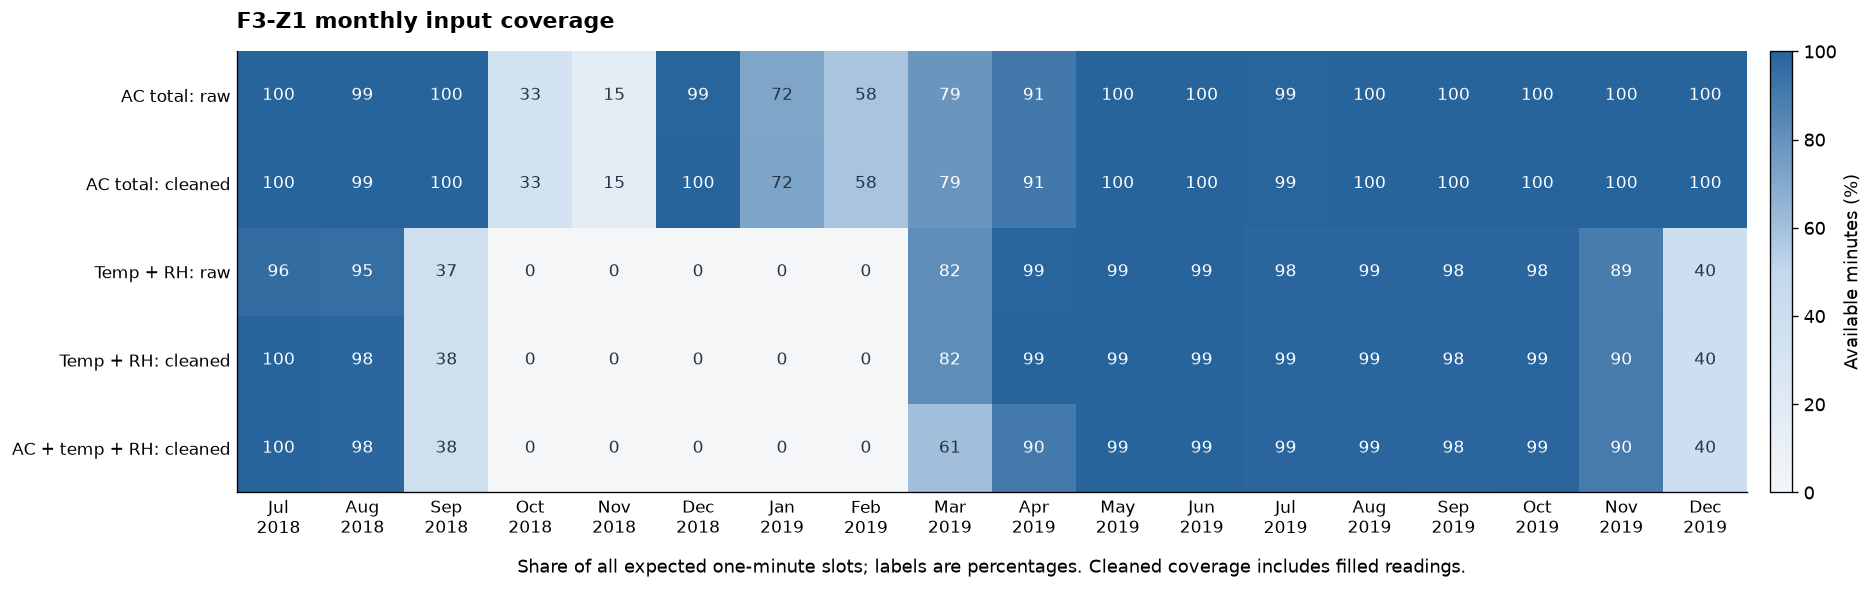

In [5]:
fields = ["raw_ac_pct", "clean_ac_pct", "raw_environment_pct", "clean_environment_pct", "clean_ac_environment_pct"]
labels = ["AC total: raw", "AC total: cleaned", "Temp + RH: raw", "Temp + RH: cleaned", "AC + temp + RH: cleaned"]
values = monthly[fields].T.to_numpy()
cmap = LinearSegmentedColormap.from_list("coverage_blue", ["#f4f6f8", "#c3d8ed", "#27649c"])
fig, ax = plt.subplots(figsize=(15.5, 4.8), layout="constrained")
image = ax.imshow(values, vmin=0, vmax=100, aspect="auto", cmap=cmap)
ax.set_yticks(range(len(labels)), labels)
ax.set_xticks(range(len(monthly)), [d.strftime("%b\n%Y") for d in monthly.index])
ax.tick_params(axis="both", length=0, labelsize=10)
for i in range(len(labels)):
    for j in range(len(monthly)):
        ax.text(j, i, f"{values[i, j]:.0f}", ha="center", va="center", fontsize=10,
                color="white" if values[i, j] >= 75 else "#243345")
ax.set_title("F3-Z1 monthly input coverage", loc="left", pad=14)
ax.set_xlabel("Share of all expected one-minute slots; labels are percentages. Cleaned coverage includes filled readings.", labelpad=12)
fig.colorbar(image, ax=ax, label="Available minutes (%)", fraction=.025, pad=.015)
fig.savefig(output_dir / "monthly_coverage.png", bbox_inches="tight")
plt.show()

### 4. Hourly export reconciliation and weather

Recompute the published hourly means from cleaned minute data using the existing 48-of-60-minute gate, then compare at the export's two-decimal precision. Weather join completeness is checked separately from timezone correctness.

In [6]:
hourly_checks = audit.reconcile_hourly(clean, hourly)
display(hourly_checks)
assert hourly_checks["availability_mismatches"].sum() == 0
assert hourly_checks["value_mismatches_above_0_01"].sum() == 0
weather = load_bangkok_era5_weather(repo_root / "baseline/data/bangkok_era5_hourly_2018-2019.csv")
weather_join = hourly.reset_index().merge(weather.reset_index(), on="Date", how="left", validate="one_to_one")
weather_checks = {
    "expected_hours": 13176, "weather_rows": len(weather),
    "duplicate_weather_timestamps": int(weather.index.duplicated().sum()),
    "missing_weather_cells": int(weather.isna().sum().sum()),
    "unmatched_F3Z1_hours": int(weather_join["outdoor_temp_C"].isna().sum()),
    "negative_rainfall_hours": int(weather["precipitation_mm"].lt(0).sum()),
    "RH_outside_0_100_hours": int((~weather["outdoor_rh_pct"].between(0, 100)).sum()),
    "dew_point_above_temperature_by_more_than_0_2C_hours": int(weather["outdoor_dew_point_C"].gt(weather["outdoor_temp_C"] + .2).sum()),
}
display(pd.DataFrame(weather_checks.items(), columns=["check", "count"]))
assert len(weather_join) == len(hourly) == len(weather)
assert weather_checks["missing_weather_cells"] == 0
assert weather_checks["unmatched_F3Z1_hours"] == 0
print("Clock alignment remains an assumption: neither building CSVs nor the cache carry a timezone offset.")

,field,hours,availability_mismatches,value_mismatches_above_0_01,maximum_absolute_difference
0,ac_kW,13176,0,0,0.0
1,plug_kW,13176,0,0,0.0
2,temp_C,13176,0,0,0.0
3,rh_pct,13176,0,0,0.0


,check,count
0,expected_hours,13176
1,weather_rows,13176
2,duplicate_weather_timestamps,0
3,missing_weather_cells,0
4,unmatched_F3Z1_hours,0
5,negative_rainfall_hours,0
6,RH_outside_0_100_hours,0
7,dew_point_above_temperature_by_more_than_0_2C_...,0


Clock alignment remains an assumption: neither building CSVs nor the cache carry a timezone offset.


### 5. Sensor flatlines

Check exact repeats on raw observations as well as cleaned data. The test interrupts runs at missing values; it cannot certify sensor calibration or exclude drift.

In [7]:
flatlines, flatline_examples = audit.flatline_profile(raw, clean)
display(flatlines)
display(flatline_examples[flatline_examples["source"].eq("raw")].head(9))
print("A lack of long exact repeats is not proof that a sensor has no drift.")
# Trace the longest cleaned-temperature plateau back to the source observations.
plateau = flatline_examples[(flatline_examples["source"] == "clean") &
                            (flatline_examples["stream"] == "temperature")].nlargest(1, "minutes").iloc[0]
window = raw.loc[plateau["start"]:plateau["end"]]
flatline_trace = pd.DataFrame([{
    "start": plateau["start"], "end": plateau["end"],
    "clean_constant_minutes": int(plateau["minutes"]),
    "raw_temperature_missing_minutes": int(window[audit.TEMP].isna().sum()),
    "raw_observed_temperature_distinct_values": int(window[audit.TEMP].nunique()),
    "raw_RH_distinct_values": int(window[audit.RH].nunique()),
}])
display(flatline_trace)


,source,stream,longest_constant_minutes,constant_runs_at_least_60min,constant_runs_at_least_360min
0,raw,temperature,57,0,0
1,raw,humidity,23,0,0
2,raw,both sensors,20,0,0
3,clean,temperature,79,1,0
4,clean,humidity,23,0,0
5,clean,both sensors,20,0,0


,source,stream,start,end,minutes
0,raw,temperature,2018-08-22 03:07:00,2018-08-22 04:03:00,57
1,raw,temperature,2018-09-05 00:21:00,2018-09-05 01:08:00,48
2,raw,temperature,2018-09-08 05:36:00,2018-09-08 06:23:00,48
3,raw,humidity,2018-07-29 05:25:00,2018-07-29 05:47:00,23
4,raw,humidity,2018-08-25 23:48:00,2018-08-26 00:10:00,23
5,raw,humidity,2018-08-20 04:52:00,2018-08-20 05:11:00,20
6,raw,both sensors,2018-08-20 04:52:00,2018-08-20 05:11:00,20
7,raw,both sensors,2018-07-29 05:25:00,2018-07-29 05:43:00,19
8,raw,both sensors,2018-08-26 23:26:00,2018-08-26 23:44:00,19


A lack of long exact repeats is not proof that a sensor has no drift.


,start,end,clean_constant_minutes,raw_temperature_missing_minutes,raw_observed_temperature_distinct_values,raw_RH_distinct_values
0,2018-08-20 04:01:00,2018-08-20 05:19:00,79,4,1,8


### 6. AC event input readiness

Retain the existing helper and compare its candidates with an independent continuity check. The 60-minute gate measures usable input windows only. The threshold uses the supplied full-period series; a future predictive evaluation must define its calibration policy separately.

In [8]:
events, event_summary, threshold_kw = audit.event_audit(raw, clean, masks, detect_ac_events, ac_on_threshold)
display(event_summary)
print(f"Existing helper AC-on threshold: {threshold_kw:.3f} kW")
problems = events[~events["continuous_state_30min"]]
display(problems[["time", "event", "continuous_state_30min", "same_state_60min_after"]].head(10))
event_monthly = events.assign(month=events["time"].dt.to_period("M").astype(str)).groupby(["month", "event"])[["continuous_state_30min", "eligible_clean_60min", "eligible_raw_observed_60min"]].sum().reset_index()

,event,helper_candidates,continuous_state_30min,eligible_clean_60min,eligible_raw_observed_60min,helper_events_not_strict,strict_events_missing_from_helper
0,start,626,626,444,355,0,0
1,stop,583,583,399,303,0,0


Existing helper AC-on threshold: 5.750 kW


,time,event,continuous_state_30min,same_state_60min_after


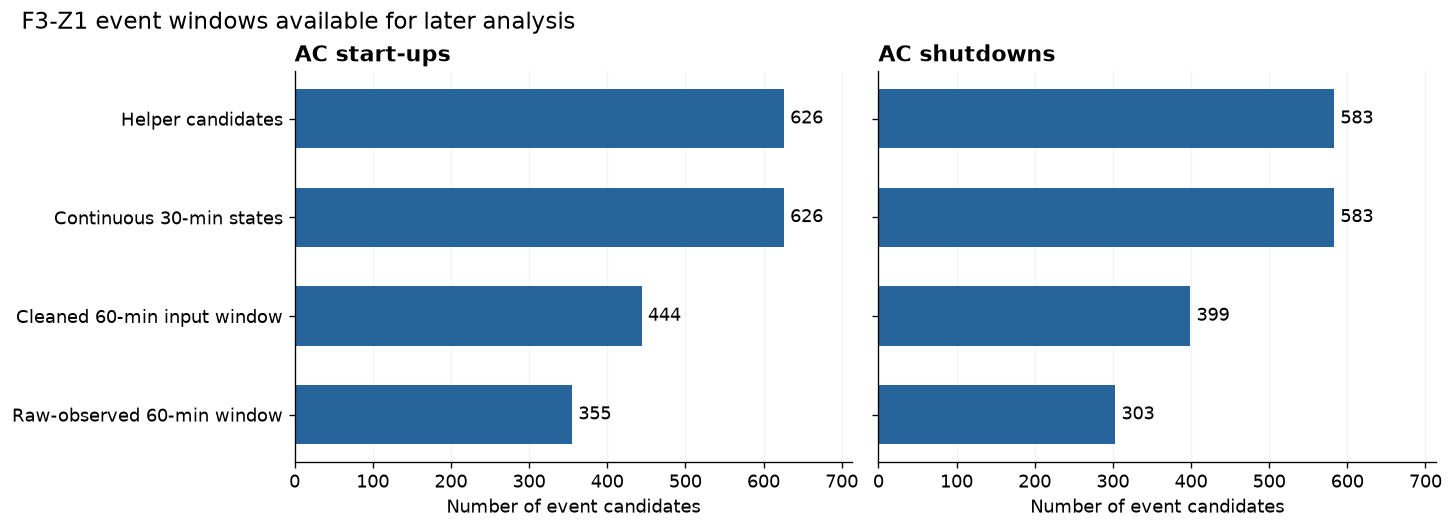

In [9]:
stages = ["helper_candidates", "continuous_state_30min", "eligible_clean_60min", "eligible_raw_observed_60min"]
labels = ["Helper candidates", "Continuous 30-min states", "Cleaned 60-min input window", "Raw-observed 60-min window"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True, sharey=True, layout="constrained")
for ax, kind, title in zip(axes, ["start", "stop"], ["AC start-ups", "AC shutdowns"]):
    row = event_summary.set_index("event").loc[kind]
    counts = [int(row[s]) for s in stages]
    ax.barh(range(4), counts, color="#27649c", height=.6)
    for y, count in enumerate(counts):
        ax.text(count + 8, y, str(count), va="center", fontsize=11)
    ax.set_yticks(range(4), labels)
    ax.set_xlim(0, max(event_summary["helper_candidates"]) * 1.14)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Number of event candidates")
    ax.grid(axis="x", alpha=.15)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
fig.suptitle("F3-Z1 event windows available for later analysis", x=.01, ha="left", fontsize=14)
fig.savefig(output_dir / "event_input_readiness.png", bbox_inches="tight")
plt.show()

### 7. Candidate daily and matched-year windows

These counts describe input availability, not a chosen training split or model result. Whole-day gates cover all expected minutes. July–August offers the clearest initial environmental overlap; exact weather, weekday and schedule matching remains later work.

In [10]:
display(sensitivity)
working_type_counts = daily["day_type"].value_counts(dropna=False).rename_axis("inferred_day_type").reset_index(name="days")
display(working_type_counts)
# Event-window attrition can differ even when monthly cleaned coverage is high.
event_overlap = events[(events["event"] == "start") & events["time"].dt.month.isin([7, 8])].copy()
event_overlap["year"] = event_overlap["time"].dt.year
event_overlap = event_overlap.groupby("year").agg(
    helper_candidates=("time", "size"),
    cleaned_60min_windows=("eligible_clean_60min", "sum"),
    raw_observed_60min_windows=("eligible_raw_observed_60min", "sum"),
)
display(event_overlap)


,period,minimum_daily_coverage_pct,working_days,clean_energy_days,raw_energy_days,clean_joint_days,raw_joint_days
0,2018 reference candidate,90,123,91,91,47,47
1,2018 reference candidate,95,123,90,90,45,35
2,2018 reference candidate,100,123,90,69,42,0
3,2019 full year,90,241,218,217,173,172
4,2019 full year,95,241,216,216,170,169
5,2019 full year,100,241,216,111,106,3
6,Jul-Aug 2018,90,42,41,41,41,41
7,Jul-Aug 2018,95,42,41,41,39,29
8,Jul-Aug 2018,100,42,41,41,37,0
9,Jul-Aug 2019,90,41,41,41,41,40


,inferred_day_type,days
0,working day,364
1,weekend,157
2,closure,28


,helper_candidates,cleaned_60min_windows,raw_observed_60min_windows
year,,,
2018,84,81,29
2019,82,78,71


## Takeaways

The interpretation below is generated from the audited inputs. It does not estimate degradation, cooling capacity, mould presence or a causal AC effect.

In [11]:
clean_gaps = gaps[gaps["source"].eq("clean")]
env_gaps = clean_gaps[clean_gaps["stream"].eq("environment")].nlargest(2, "minutes")
ac_gaps = clean_gaps[clean_gaps["stream"].eq("ac")].nlargest(3, "minutes")
base95 = sensitivity[sensitivity["minimum_daily_coverage_pct"].eq(95)].set_index("period")
starts = event_summary.set_index("event").loc["start"]
summary = {
    "expected_minutes": len(clean), "expected_hours": len(hourly),
    "clean_AC_coverage_pct": float(masks["clean"]["ac"].mean() * 100),
    "raw_AC_coverage_pct": float(masks["raw"]["ac"].mean() * 100),
    "clean_environment_coverage_pct": float(masks["clean"]["environment"].mean() * 100),
    "raw_environment_coverage_pct": float(masks["raw"]["environment"].mean() * 100),
    "clean_joint_coverage_pct": float(masks["clean"]["ac_environment"].mean() * 100),
    "raw_joint_coverage_pct": float(masks["raw"]["ac_environment"].mean() * 100),
    "AC_on_threshold_kW": threshold_kw,
    "weather": weather_checks,
    "event_summary": json.loads(event_summary.to_json(orient="records")),
    "daily_95pct_gate": json.loads(base95.reset_index().to_json(orient="records")),
    "largest_environment_gaps": json.loads(env_gaps.to_json(orient="records", date_format="iso")),
    "largest_AC_total_gaps": json.loads(ac_gaps.to_json(orient="records", date_format="iso")),
    "flatlines": json.loads(flatlines.to_json(orient="records")),
    "flatline_trace": json.loads(flatline_trace.to_json(orient="records", date_format="iso")),
    "Jul_Aug_startup_windows": json.loads(event_overlap.reset_index().to_json(orient="records")),
}
notes = [
    f"**Input structure:** {len(clean):,} one-minute slots; no duplicate or off-grid source timestamps. Hourly exports reconcile with cleaned minute readings.",
    f"**Full-period availability:** {summary['clean_AC_coverage_pct']:.2f}% AC total, {summary['clean_environment_coverage_pct']:.2f}% paired temperature/RH and {summary['clean_joint_coverage_pct']:.2f}% jointly available, including interpolation.",
    f"**Start-up windows:** {int(starts['helper_candidates'])} helper candidates; {int(starts['continuous_state_30min'])} pass continuous-state checks, {int(starts['eligible_clean_60min'])} have a usable cleaned 60-minute window, and {int(starts['eligible_raw_observed_60min'])} also avoid filled source readings.",
    "**Comparison boundary:** use eligible July–August periods for the initial cross-year environmental audit. Do not use whole-year indoor averages or bridge outages. Energy-only inputs have a different availability window.",
    "**Before modelling:** review these eligibility choices; resolve/retain the clock-alignment assumption and use continuity-aware event windows. Missingness and non-flatline checks cannot rule out sensor drift or establish healthy AC operation.",
]
display(Markdown("\n\n".join(notes)))

**Input structure:** 790,560 one-minute slots; no duplicate or off-grid source timestamps. Hourly exports reconcile with cleaned minute readings.

**Full-period availability:** 86.06% AC total, 63.62% paired temperature/RH and 61.92% jointly available, including interpolation.

**Start-up windows:** 626 helper candidates; 626 pass continuous-state checks, 444 have a usable cleaned 60-minute window, and 355 also avoid filled source readings.

**Comparison boundary:** use eligible July–August periods for the initial cross-year environmental audit. Do not use whole-year indoor averages or bridge outages. Energy-only inputs have a different availability window.

**Before modelling:** review these eligibility choices; resolve/retain the clock-alignment assumption and use continuity-aware event windows. Missingness and non-flatline checks cannot rule out sensor drift or establish healthy AC operation.

### Reproducible evidence

CSV tables retain exact counts and denominators. The manifest records source file hashes and the checked runtime. All new outputs stay under this audit's output folder; raw files, cleaned outputs, existing baselines and the shared helper remain unchanged.

In [12]:
tables = {"timeline_checks": timeline, "channel_quality": profile, "monthly_coverage": monthly,
          "daily_coverage": daily, "daily_gate_sensitivity": sensitivity, "missing_intervals_over_15min": gaps,
          "hourly_reconciliation": hourly_checks, "sensor_flatlines": flatlines,
          "sensor_flatline_examples": flatline_examples, "AC_event_input_checks": events,
          "AC_event_summary": event_summary, "AC_event_monthly": event_monthly,
          "meter_pair_checks": pair_checks, "flatline_trace": flatline_trace, "Jul_Aug_startup_windows": event_overlap.reset_index()}
for name, table in tables.items():
    table.to_csv(output_dir / f"{name}.csv", index=isinstance(table.index, pd.DatetimeIndex))
(output_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
(output_dir / "provenance.json").write_text(json.dumps(record, indent=2) + "\n")
for item in manifest:
    path = repo_root / item["path"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], f"Input changed: {item['path']}"
print("Audit outputs saved; input hashes unchanged. No model was fitted.")

Audit outputs saved; input hashes unchanged. No model was fitted.
